# ADRC cohort preprocessing validation: V1 vs V2

This notebook validates the two completed preprocessing pipelines for the 10 selected subjects. It reads existing outputs, creates missing QC derivatives when possible, skips unavailable inputs, and never reruns preprocessing.

## 1. Configuration and output layout

In [153]:
from pathlib import Path
import shutil, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SUBJECTS = ['D0007','D0051','D0057','D0066','D0089','D0064','D0083','D0087','D0106','D0128']
V1_ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/test/preprocess_v1_qc')
V2_ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/test/preprocess_v2')
QC_ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation')
QC_ROOT.mkdir(parents=True, exist_ok=True)
VIS_ROOT = QC_ROOT / 'visualization_for_three_samples'
VIS_ROOT.mkdir(parents=True, exist_ok=True)
RUN_EDDY_QUAD = True
OVERWRITE = False

def existing(path): return Path(path).is_file()
def first_file(root, pattern):
    hits = sorted(Path(root).rglob(pattern)) if Path(root).exists() else []
    return hits[0] if hits else None
def run_optional(command, output=None):
    if output is not None and Path(output).exists() and not OVERWRITE: return 'exists'
    if shutil.which(str(command[0])) is None: return f'missing command: {command[0]}'
    result = subprocess.run([str(x) for x in command], capture_output=True, text=True)
    return 'completed' if result.returncode == 0 else f'failed: {result.stderr[-300:]}'

## 2. Acquisition metadata and actual Eddy configuration

This section records the phase-encoding/acquisition parameters preserved by `dwifslpreproc`, checks for reverse-PE evidence, and reports the actual Eddy command. A `rpe_pair`-equivalent configuration requires the reverse-PE pair and topup input; absence is reported rather than inferred.

In [154]:
def eddy_dir(root):
    required = ['dwi_post_eddy.nii.gz','eddy_indices.txt','eddy_config.txt','eddy_mask.nii','bvals']
    candidates = sorted((Path(root)/'eddy_scratch').glob('dwifslpreproc-tmp-*')) if (Path(root)/'eddy_scratch').exists() else []
    good = [d for d in candidates if all((d/f).exists() for f in required)]
    return good[-1] if good else None

metadata_rows = []
for subject in SUBJECTS:
    for pipeline, root in [('v1', V1_ROOT/subject), ('v2', V2_ROOT/subject)]:
        d = eddy_dir(root)
        command_file = d / 'command.txt' if d and (d / 'command.txt').exists() else None
        row = {'subject':subject,'pipeline':pipeline,'status':'missing','eddy_scratch':str(d) if d else '', 'pe_direction':'','readout_time':np.nan,'reverse_pe_b0_pair':False,'forward_b0':False,'dwifslpreproc_mode':'unknown','susceptibility_correction':'not confirmed','actual_dwifslpreproc_command':''}
        if d:
            row['status']='available'
            command = command_file.read_text().strip() if command_file else ''
            row['actual_dwifslpreproc_command'] = command
            row['pe_direction'] = command.split('-pe_dir',1)[1].split()[0] if '-pe_dir' in command else ''
            row['readout_time'] = float(command.split('-readout_time',1)[1].split()[0]) if '-readout_time' in command else np.nan
            row['reverse_pe_b0_pair'] = (root/f'{subject}_se_epi_pair.nii.gz').exists() or (root/f'{subject}_rev_seepi_pair.nii.gz').exists()
            row['forward_b0'] = (root/f'{subject}_forward_b0.nii.gz').exists()
            row['dwifslpreproc_mode'] = 'rpe_pair' if '-rpe_pair' in command else ('rpe_none' if '-rpe_none' in command else 'other/unknown')
            row['susceptibility_correction'] = 'topup via paired reverse-PE b0' if row['dwifslpreproc_mode']=='rpe_pair' and row['reverse_pe_b0_pair'] else 'limited/not confirmed'
        metadata_rows.append(row)
acquisition_metadata = pd.DataFrame(metadata_rows)
acquisition_metadata.to_csv(QC_ROOT/'acquisition_eddy_metadata.csv', index=False)
display(acquisition_metadata[['subject','pipeline','status','pe_direction','readout_time','forward_b0','reverse_pe_b0_pair','dwifslpreproc_mode','susceptibility_correction']])

,subject,pipeline,status,pe_direction,readout_time,forward_b0,reverse_pe_b0_pair,dwifslpreproc_mode,susceptibility_correction
0,D0007,v1,available,PA,0.076191,True,True,rpe_pair,topup via paired reverse-PE b0
1,D0007,v2,available,PA,0.076191,True,True,rpe_pair,topup via paired reverse-PE b0
2,D0051,v1,available,PA,0.076191,True,True,rpe_pair,topup via paired reverse-PE b0
3,D0051,v2,available,PA,0.076191,True,True,rpe_pair,topup via paired reverse-PE b0
4,D0057,v1,available,PA,0.119063,True,True,rpe_pair,topup via paired reverse-PE b0
5,D0057,v2,available,PA,0.119063,True,True,rpe_pair,topup via paired reverse-PE b0
6,D0066,v1,available,PA,0.076191,True,True,rpe_pair,topup via paired reverse-PE b0
7,D0066,v2,available,PA,0.076191,True,True,rpe_pair,topup via paired reverse-PE b0
8,D0089,v1,available,PA,0.076191,True,True,rpe_pair,topup via paired reverse-PE b0
9,D0089,v2,available,PA,0.076191,True,True,rpe_pair,topup via paired reverse-PE b0


## 3. Eddy correction QC

All 10 subjects and both pipelines are included when files exist. Motion is summarized per volume; outliers are counted per scan-slice. `eddy_quad` uses the preserved Eddy basename, `eddy_indices.txt`, `eddy_config.txt`, `eddy_mask.nii`, and `bvals`.

In [155]:
def numbers(path, skiprows=0):
    if path is None or not Path(path).exists() or Path(path).stat().st_size == 0: return None
    try: return np.loadtxt(path, skiprows=skiprows, ndmin=2)
    except (OSError, ValueError): return None

eddy_rows=[]
for subject in SUBJECTS:
    for pipeline, root in [('v1',V1_ROOT/subject),('v2',V2_ROOT/subject)]:
        d=eddy_dir(root); row={'subject':subject,'pipeline':pipeline,'status':'missing','scratch_dir':str(d) if d else ''}
        if d:
            row['status']='available'
            for label, fn in [('movement_rms','dwi_post_eddy.eddy_movement_rms'),('restricted_rms','dwi_post_eddy.eddy_restricted_movement_rms')]:
                x=numbers(d/fn)
                if x is not None: row[f'{label}_mean']=float(np.nanmean(x)); row[f'{label}_max']=float(np.nanmax(x))
            x=numbers(d/'dwi_post_eddy.eddy_outlier_map',skiprows=1)
            if x is not None: row['outlier_flagged']=int(np.count_nonzero(x)); row['outlier_evaluated']=int(x.size); row['outlier_percent']=float(100*np.mean(x!=0))
            if RUN_EDDY_QUAD and shutil.which('eddy_quad'):
                out=QC_ROOT/'eddy_quad_reports'/subject/pipeline; out.mkdir(parents=True,exist_ok=True)
                if any(out.iterdir()) and not OVERWRITE: row['eddy_quad_status']='cached: report exists'
                else:
                    cmd=['eddy_quad',str(d/'dwi_post_eddy'),'-idx',str(d/'eddy_indices.txt'),'-par',str(d/'eddy_config.txt'),'-m',str(d/'eddy_mask.nii'),'-b',str(d/'bvals'),'-o',str(out)]
                    r=subprocess.run(cmd,capture_output=True,text=True); row['eddy_quad_status']='completed' if r.returncode==0 else f'failed: {r.stderr[-300:]}'
            elif RUN_EDDY_QUAD: row['eddy_quad_status']='skipped: eddy_quad not found'
        eddy_rows.append(row)
eddy_summary=pd.DataFrame(eddy_rows)
eddy_summary.to_csv(QC_ROOT/'eddy_qc_summary_10_subjects.csv',index=False)
display(eddy_summary)

,subject,pipeline,status,scratch_dir,movement_rms_mean,movement_rms_max,restricted_rms_mean,restricted_rms_max,outlier_flagged,outlier_evaluated,outlier_percent,eddy_quad_status
0,D0007,v1,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,0.351981,1.021767,0.332899,1.004140,0,3294,0.000000,"failed: c/QUAD/quad.py"", line 162, in main\n ..."
1,D0007,v2,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,0.344238,1.006012,0.325396,0.978002,0,3294,0.000000,"failed: c/QUAD/quad.py"", line 162, in main\n ..."
2,D0051,v1,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,0.172886,0.461851,0.158315,0.460793,0,3294,0.000000,"failed: c/QUAD/quad.py"", line 162, in main\n ..."
3,D0051,v2,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,0.171287,0.468295,0.156313,0.467527,0,3294,0.000000,"failed: c/QUAD/quad.py"", line 162, in main\n ..."
4,D0057,v1,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,0.359175,1.070794,0.329304,1.058345,0,3294,0.000000,"failed: c/QUAD/quad.py"", line 162, in main\n ..."
5,D0057,v2,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,0.363792,1.095921,0.333680,1.082191,0,3294,0.000000,"failed: c/QUAD/quad.py"", line 162, in main\n ..."
6,D0066,v1,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,0.146452,0.369877,0.135674,0.352151,0,3294,0.000000,"failed: c/QUAD/quad.py"", line 162, in main\n ..."
7,D0066,v2,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,0.142046,0.357252,0.130958,0.337835,0,3294,0.000000,"failed: c/QUAD/quad.py"", line 162, in main\n ..."
8,D0089,v1,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,0.258777,0.628662,0.235503,0.615956,0,3294,0.000000,"failed: c/QUAD/quad.py"", line 162, in main\n ..."
9,D0089,v2,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,0.257712,0.622906,0.234547,0.610635,0,3294,0.000000,"failed: c/QUAD/quad.py"", line 162, in main\n ..."


### 3.1 Movement RMS and volume-wise motion curves

The following cell creates the requested absolute/relative RMS summaries, per-volume translation/rotation curves, and outlier concentration by volume.

In [156]:
motion_rows=[]; outlier_volume_rows=[]
for subject in SUBJECTS:
    for pipeline,root in [('v1',V1_ROOT/subject),('v2',V2_ROOT/subject)]:
        d=eddy_dir(root)
        if d is None: continue
        motion_path=d/'dwi_post_eddy.eddy_movement_rms'; params_path=d/'dwi_post_eddy.eddy_parameters'; outlier_path=d/'dwi_post_eddy.eddy_outlier_map'
        motion=numbers(motion_path)
        if motion is not None:
            row={'subject':subject,'pipeline':pipeline,'mean_absolute_rms':float(np.nanmean(np.abs(motion[:,0]))),'maximum_absolute_rms':float(np.nanmax(np.abs(motion[:,0])))}
            if motion.shape[1]>=2: row['mean_relative_rms']=float(np.nanmean(np.abs(motion[:,1]))); row['maximum_relative_rms']=float(np.nanmax(np.abs(motion[:,1])))
            motion_rows.append(row)
        params=numbers(params_path)
        if params is not None and params.shape[1]>=6:
            curve=pd.DataFrame(params[:,:6],columns=['rotation_x','rotation_y','rotation_z','translation_x','translation_y','translation_z'])
            curve.insert(0,'volume',np.arange(len(curve))); curve.insert(0,'pipeline',pipeline); curve.insert(0,'subject',subject)
            curve.to_csv(QC_ROOT/f'{subject}_{pipeline}_translation_rotation_by_volume.csv',index=False)
            ax=curve.plot(x='volume',y=['translation_x','translation_y','translation_z'],title=f'{subject} {pipeline} translations'); ax.figure.savefig(QC_ROOT/f'{subject}_{pipeline}_translations.png',dpi=150); plt.close(ax.figure)
            ax=curve.plot(x='volume',y=['rotation_x','rotation_y','rotation_z'],title=f'{subject} {pipeline} rotations'); ax.figure.savefig(QC_ROOT/f'{subject}_{pipeline}_rotations.png',dpi=150); plt.close(ax.figure)
        outliers=numbers(outlier_path,skiprows=1)
        if outliers is not None:
            counts=np.count_nonzero(outliers,axis=1)
            for volume,count in enumerate(counts): outlier_volume_rows.append({'subject':subject,'pipeline':pipeline,'volume':volume,'outlier_slices':int(count),'total_slices':int(outliers.shape[1]),'outlier_percent':float(100*count/outliers.shape[1])})
motion_detail=pd.DataFrame(motion_rows); motion_detail.to_csv(QC_ROOT/'eddy_motion_summary_detailed.csv',index=False)
outlier_by_volume=pd.DataFrame(outlier_volume_rows); outlier_by_volume.to_csv(QC_ROOT/'eddy_outliers_by_volume.csv',index=False)
display(motion_detail); display(outlier_by_volume[outlier_by_volume.outlier_slices>0])

,subject,pipeline,mean_absolute_rms,maximum_absolute_rms,mean_relative_rms,maximum_relative_rms
0,D0007,v1,0.519729,1.021767,0.184232,0.446985
1,D0007,v2,0.513448,1.006012,0.175027,0.426589
2,D0051,v1,0.238696,0.397619,0.107076,0.461851
3,D0051,v2,0.236541,0.391737,0.106033,0.468295
4,D0057,v1,0.503902,1.021478,0.214449,1.070794
5,D0057,v2,0.510258,1.045748,0.217326,1.095921
6,D0066,v1,0.212302,0.369877,0.080601,0.321464
7,D0066,v2,0.205203,0.357252,0.078888,0.304138
8,D0089,v1,0.390589,0.628662,0.126964,0.362433
9,D0089,v2,0.389128,0.622906,0.126296,0.361103


,subject,pipeline,volume,outlier_slices,total_slices,outlier_percent
503,D0128,v1,17,1,122,0.819672
530,D0128,v2,17,1,122,0.819672


### 3.2 Paired V1/V2 RMS comparison

Two panels compare V1 and V2 for mean absolute RMS and maximum relative RMS. Lines connect paired values from the same subject.

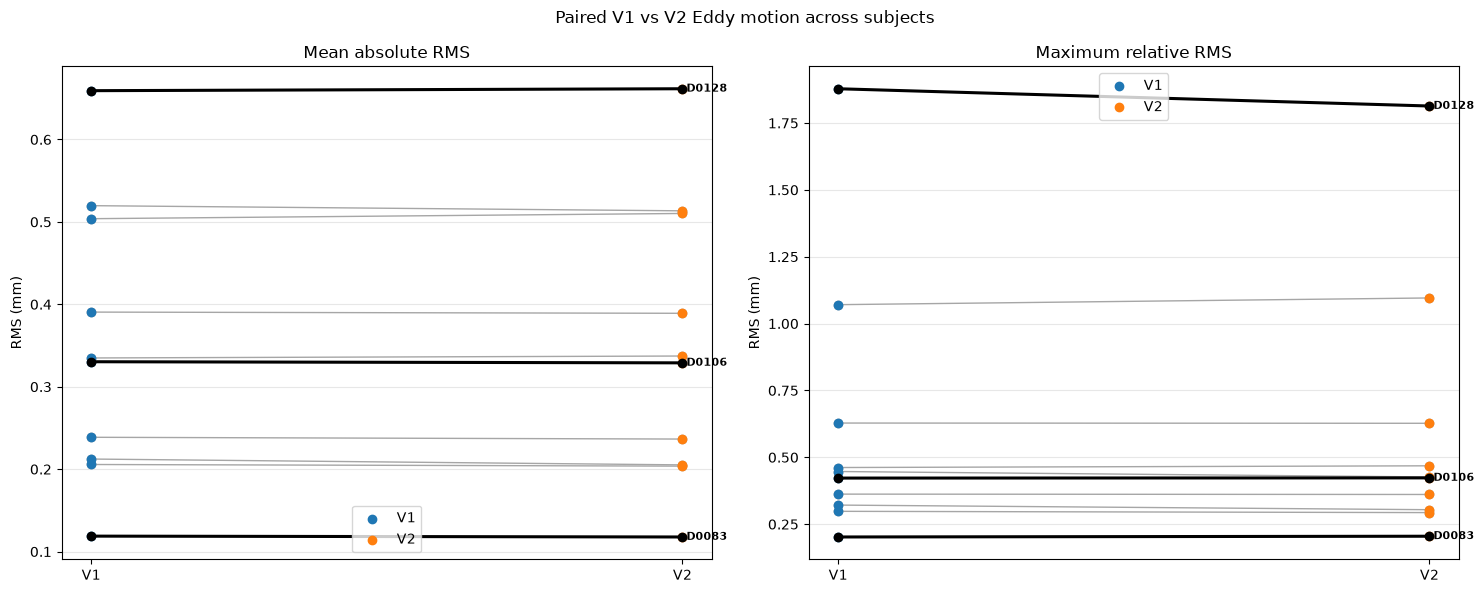

Regenerated: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/eddy_paired_rms_plot.png


In [157]:
selected_file = QC_ROOT / 'representative_subjects.csv'
selected_table = pd.read_csv(selected_file) if selected_file.exists() else (reps if 'reps' in globals() else pd.DataFrame())
selected_subjects = set(selected_table['subject'].dropna().astype(str)) if 'subject' in selected_table.columns else set()
plot_data = motion_detail.dropna(subset=['mean_absolute_rms','maximum_relative_rms']).copy()
plot_data = plot_data[plot_data['pipeline'].isin(['v1','v2'])]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, metric, title, ylabel in zip(axes, ['mean_absolute_rms','maximum_relative_rms'], ['Mean absolute RMS','Maximum relative RMS'], ['RMS (mm)','RMS (mm)']):
    wide = plot_data.pivot(index='subject', columns='pipeline', values=metric)
    for subject, values in wide.iterrows():
        if {'v1','v2'}.issubset(values.dropna().index):
            highlighted = subject in selected_subjects
            ax.plot(['V1','V2'], [values['v1'],values['v2']], color='black' if highlighted else '0.65', linewidth=2.2 if highlighted else 1.0, marker='o', zorder=3 if highlighted else 1)
            if highlighted: ax.text('V2', values['v2'], f' {subject}', va='center', fontsize=8, fontweight='bold')
    for pipeline, color in [('v1','tab:blue'),('v2','tab:orange')]:
        vals=wide[pipeline] if pipeline in wide else pd.Series(dtype=float); ax.scatter([pipeline.upper()]*len(vals), vals, color=color, label=pipeline.upper(), zorder=2)
    ax.set_title(title); ax.set_ylabel(ylabel); ax.grid(axis='y',alpha=0.3); ax.legend()
fig.suptitle('Paired V1 vs V2 Eddy motion across subjects'); fig.tight_layout()
plot_path = QC_ROOT/'eddy_paired_rms_plot.png'
fig.savefig(plot_path,dpi=180)
display(fig)
plt.close(fig)
print('Regenerated:',plot_path)

### 3.3 Outlier slices and volumes

Only subjects/pipelines with at least one outlier are visualized. The table identifies the volume and slice, then compares the corresponding RMS with the subject/pipeline RMS distribution.

Cached outlier map: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/outlier_maps/D0128_v1_outlier_map.png
Cached outlier map: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/outlier_maps/D0128_v2_outlier_map.png
Cached: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/eddy_outlier_locations.csv


,subject,pipeline,volume,slice,outlier_flag,rms_at_volume,motion_spike_95th_percentile
0,D0128,v1,17,58,1,0.438962,False
1,D0128,v2,17,58,1,0.436404,False


Saved: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/eddy_outlier_locations.csv


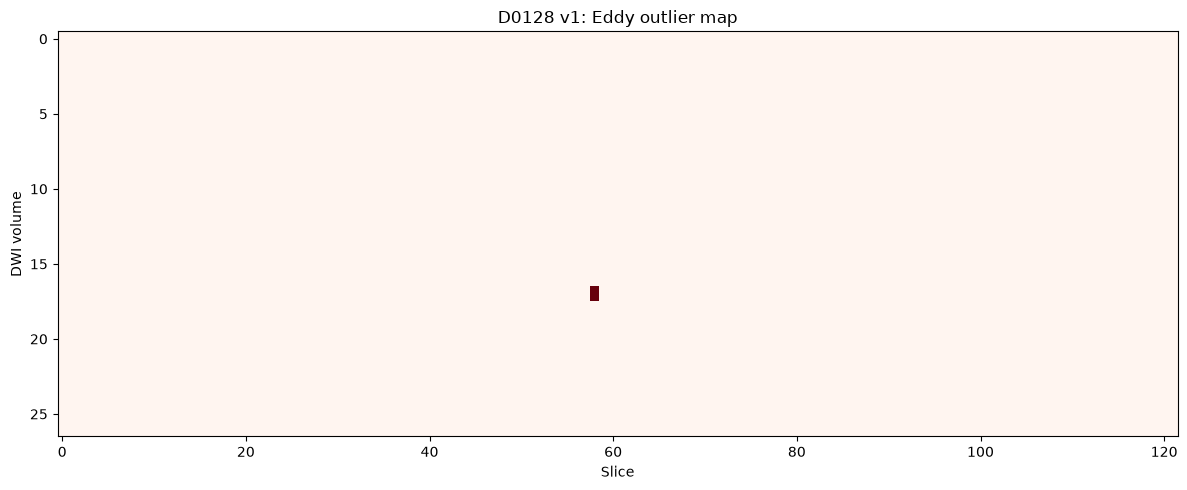

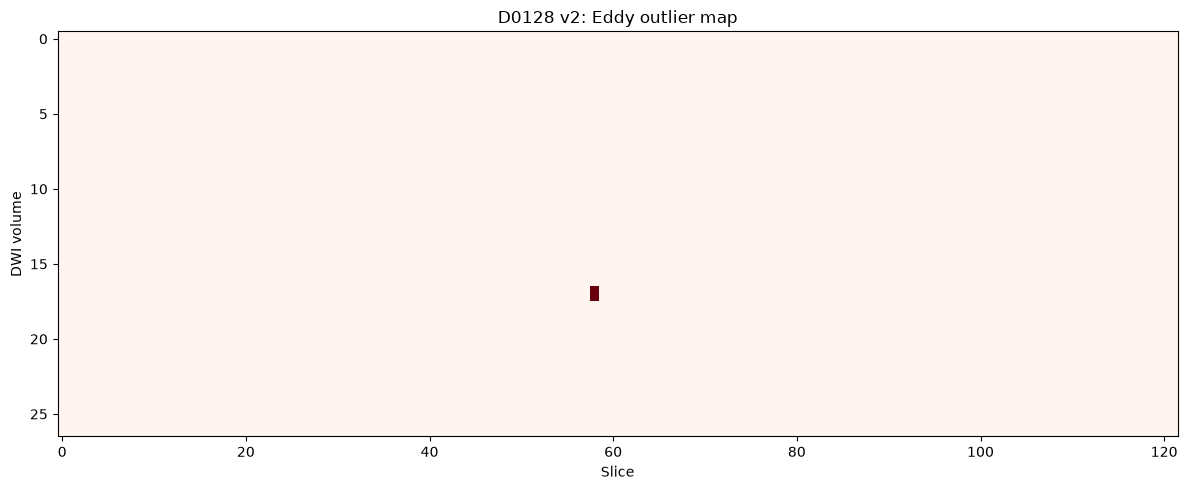

In [158]:
outlier_location_rows = []
outlier_plot_root = QC_ROOT / 'outlier_maps'
outlier_plot_root.mkdir(parents=True, exist_ok=True)
for subject in SUBJECTS:
    for pipeline, root in [('v1', V1_ROOT / subject), ('v2', V2_ROOT / subject)]:
        d = eddy_dir(root)
        if d is None: continue
        outliers = numbers(d / 'dwi_post_eddy.eddy_outlier_map', skiprows=1)
        if outliers is None or not np.any(outliers != 0): continue
        motion = numbers(d / 'dwi_post_eddy.eddy_movement_rms')
        flagged = np.argwhere(outliers != 0)
        motion_values = np.abs(motion).max(axis=1) if motion is not None else np.full(outliers.shape[0], np.nan)
        threshold = np.nanpercentile(motion_values, 95) if np.isfinite(motion_values).any() else np.nan
        for volume, slice_index in flagged:
            rms = float(motion_values[volume]) if volume < len(motion_values) else np.nan
            outlier_location_rows.append({'subject': subject, 'pipeline': pipeline, 'volume': int(volume), 'slice': int(slice_index), 'outlier_flag': int(outliers[volume, slice_index]), 'rms_at_volume': rms, 'motion_spike_95th_percentile': bool(np.isfinite(rms) and np.isfinite(threshold) and rms >= threshold)})
        fig, ax = plt.subplots(figsize=(12, 5))
        ax.imshow(outliers, aspect='auto', interpolation='nearest', cmap='Reds', vmin=0, vmax=1)
        ax.set_title(f'{subject} {pipeline}: Eddy outlier map')
        ax.set_xlabel('Slice'); ax.set_ylabel('DWI volume')
        fig.tight_layout()
        output = outlier_plot_root / f'{subject}_{pipeline}_outlier_map.png'
        if OVERWRITE or not output.exists(): fig.savefig(output, dpi=180); print('Saved outlier map:', output)
        else: print('Cached outlier map:', output)
outlier_locations = pd.DataFrame(outlier_location_rows)
outlier_location_csv = QC_ROOT / 'eddy_outlier_locations.csv'
if OVERWRITE or not outlier_location_csv.exists(): outlier_locations.to_csv(outlier_location_csv, index=False)
else: print('Cached:', outlier_location_csv)
if outlier_locations.empty: print('No outlier slices found in the available Eddy maps.')
else: display(outlier_locations)
print('Saved:', QC_ROOT / 'eddy_outlier_locations.csv')

### 3.4 Outlier image inspection and model residuals

In [159]:
VIS_VOLUME = 2
outlier_slice_root = VIS_ROOT / 'eddy_outlier_slices'
eddy_residual_root = VIS_ROOT / 'eddy_model_residuals'
outlier_slice_root.mkdir(parents=True, exist_ok=True)
eddy_residual_root.mkdir(parents=True, exist_ok=True)

# Create pre-/post-Eddy images for each flagged volume, including adjacent volumes.
if 'outlier_locations' in globals() and not outlier_locations.empty:
    for row in outlier_locations.itertuples(index=False):
        root = V1_ROOT if row.pipeline == 'v1' else V2_ROOT
        d = eddy_dir(root / row.subject)
        post = d / 'dwi_post_eddy.nii.gz' if d is not None else None
        pre = d / 'eddy_in.nii' if d is not None else None
        for volume in sorted({max(0, int(row.volume)-1), int(row.volume), int(row.volume)+1}):
            for label, source in [('pre_eddy', pre), ('post_eddy', post)]:
                target = outlier_slice_root / f'{row.subject}_{row.pipeline}_{label}_vol{volume}_slice{row.slice}.nii.gz'
                if source is not None and source.exists() and (OVERWRITE or not target.exists()):
                    run_optional(['mrconvert', str(source), str(target), '-coord', '3', str(volume), '-coord', '2', str(row.slice), '-force'], target)
    print('Outlier slice images:', outlier_slice_root)
else: print('No outlier locations available; no outlier slice images generated.')

# Extract only the official Eddy model-fit residuals; never substitute a difference image.
selected = pd.read_csv(QC_ROOT / 'representative_subjects.csv') if (QC_ROOT / 'representative_subjects.csv').exists() else (reps if 'reps' in globals() else pd.DataFrame())
selected_subjects = selected['subject'].dropna().astype(str).tolist()[:3] if 'subject' in selected.columns else []
for subject in selected_subjects:
    for pipeline, root in [('v1', V1_ROOT / subject), ('v2', V2_ROOT / subject)]:
        d = eddy_dir(root)
        if d is None: continue
        candidates = sorted(d.glob('dwi_post_eddy.eddy_residuals*'))
        if not candidates:
            print(subject, pipeline, ': model-fit residual unavailable')
            continue
        source = candidates[0]
        volumes = [VIS_VOLUME] + ([17] if subject == 'D0128' else [])
        for volume in volumes:
            target = eddy_residual_root / f'{subject}_{pipeline}_eddy_model_residual_vol{volume}.nii.gz'
            if OVERWRITE or not target.exists():
                run_optional(['mrconvert', str(source), str(target), '-coord', '3', str(volume), '-force'], target)
            else: print('Cached:', target)
print('Official Eddy model residuals (vol2; D0128 also vol17):', eddy_residual_root)

Outlier slice images: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/eddy_outlier_slices
D0083 v1 : model-fit residual unavailable
D0083 v2 : model-fit residual unavailable
D0106 v1 : model-fit residual unavailable
D0106 v2 : model-fit residual unavailable
D0128 v1 : model-fit residual unavailable
D0128 v2 : model-fit residual unavailable
Official Eddy model residuals (vol2; D0128 also vol17): /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/eddy_model_residuals


### 3.5 Representative volume extraction

In [160]:
# These are post-Eddy 3D diffusion volumes, not newly computed mean b0 images.
# vol2 is the common reference; vol17 is the detected D0128 outlier volume.
d0128_volume_root = VIS_ROOT / 'post_eddy_volumes'
d0128_volume_root.mkdir(parents=True, exist_ok=True)
for subject in ('D0083', 'D0087', 'D0128'):
  for pipeline, root in [('v1', V1_ROOT / subject), ('v2', V2_ROOT / subject)]:
    d = eddy_dir(root)
    source = d / 'dwi_post_eddy.nii.gz' if d is not None else None
    volumes = (2, 17) if subject == 'D0128' else (2,)
    for volume in volumes:
        target = d0128_volume_root / f'{subject}_{pipeline}_post_eddy_vol{volume}.nii.gz'
        if source is None or not source.exists():
            print('Missing post-Eddy DWI:', pipeline)
        elif OVERWRITE or not target.exists():
            run_optional(['mrconvert', str(source), str(target), '-coord', '3', str(volume), '-force'], target)
        else: print('Cached:', target)
print('D0128 volume images:', d0128_volume_root)

Cached: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/post_eddy_volumes/D0083_v1_post_eddy_vol2.nii.gz
Cached: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/post_eddy_volumes/D0083_v2_post_eddy_vol2.nii.gz
Cached: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/post_eddy_volumes/D0087_v1_post_eddy_vol2.nii.gz
Cached: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/post_eddy_volumes/D0087_v2_post_eddy_vol2.nii.gz
Cached: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/post_eddy_volumes/D0128_v1_post_eddy_vol2.nii.gz
Cached: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/post_eddy_volumes/D0128_v1_post_eddy_vol17.nii.gz
Cached: /mnt/ne

### 3.6 Eddy acquisition and registration inputs

In [161]:
# This cell inventories the files needed for overlay; it does not perform registration.
overlay_rows = []
for subject in SUBJECTS:
    for pipeline, root in [('v1', V1_ROOT / subject), ('v2', V2_ROOT / subject)]:
        b0 = root / f'{subject}_corrected_mean_b0.nii.gz'
        fs_t1 = Path('/mnt/newStor/paros/paros_WORK/xintong/test/freesurfer_subjects') / subject / 'mri' / 'orig.mgz'
        t1_status = 'available in FreeSurfer (orig.mgz)' if fs_t1.exists() else 'missing from FreeSurfer subject'
        overlay_rows.append({'subject': subject, 'pipeline': pipeline, 'corrected_mean_b0': str(b0), 'b0_status': 'available' if b0.exists() else 'missing', 'T1_path': str(fs_t1), 'T1_status': t1_status})
overlay_inputs = pd.DataFrame(overlay_rows)
overlay_inputs.to_csv(QC_ROOT / 'b0_t1_overlay_inputs.csv', index=False)
display(overlay_inputs)
print('Required for overlay: corrected_mean_b0 + native T1 (and a registration transform if not already aligned).')
print('Saved:', QC_ROOT / 'b0_t1_overlay_inputs.csv')

,subject,pipeline,corrected_mean_b0,b0_status,T1_path,T1_status
0,D0007,v1,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,available,/mnt/newStor/paros/paros_WORK/xintong/test/fre...,available in FreeSurfer (orig.mgz)
1,D0007,v2,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,available,/mnt/newStor/paros/paros_WORK/xintong/test/fre...,available in FreeSurfer (orig.mgz)
2,D0051,v1,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,available,/mnt/newStor/paros/paros_WORK/xintong/test/fre...,available in FreeSurfer (orig.mgz)
3,D0051,v2,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,available,/mnt/newStor/paros/paros_WORK/xintong/test/fre...,available in FreeSurfer (orig.mgz)
4,D0057,v1,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,available,/mnt/newStor/paros/paros_WORK/xintong/test/fre...,available in FreeSurfer (orig.mgz)
5,D0057,v2,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,available,/mnt/newStor/paros/paros_WORK/xintong/test/fre...,available in FreeSurfer (orig.mgz)
6,D0066,v1,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,available,/mnt/newStor/paros/paros_WORK/xintong/test/fre...,available in FreeSurfer (orig.mgz)
7,D0066,v2,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,available,/mnt/newStor/paros/paros_WORK/xintong/test/fre...,available in FreeSurfer (orig.mgz)
8,D0089,v1,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,available,/mnt/newStor/paros/paros_WORK/xintong/test/fre...,available in FreeSurfer (orig.mgz)
9,D0089,v2,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,available,/mnt/newStor/paros/paros_WORK/xintong/test/fre...,available in FreeSurfer (orig.mgz)


Required for overlay: corrected_mean_b0 + native T1 (and a registration transform if not already aligned).
Saved: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/b0_t1_overlay_inputs.csv


### 3.7 Eddy_quad standard QC report

In [162]:
report_rows=[]
report_root=QC_ROOT/'eddy_quad_reports'
if report_root.exists():
    for path in sorted(report_root.rglob('*')):
        if path.is_file():
            text=path.read_text(errors='replace') if path.suffix.lower() in ('.txt','.log','.html') else ''
            warnings=[line.strip() for line in text.splitlines() if any(word in line.lower() for word in ('warning','error','failed'))]
            report_rows.append({'file':str(path),'size_bytes':path.stat().st_size,'warning_or_error_lines':' | '.join(warnings[:10])})
eddy_quad_inventory=pd.DataFrame(report_rows)
eddy_quad_inventory.to_csv(QC_ROOT/'eddy_quad_report_inventory.csv',index=False)
display(eddy_quad_inventory)
print('Residual/model-fit files are listed above when produced by eddy_quad; an empty inventory means eddy_quad was not run or produced no files.')

""


Residual/model-fit files are listed above when produced by eddy_quad; an empty inventory means eddy_quad was not run or produced no files.


In [163]:
paired=eddy_summary[eddy_summary.status=='available'].pivot(index='subject',columns='pipeline',values=['movement_rms_mean','restricted_rms_mean','outlier_percent'])
paired.columns=[f'{a}_{b}' for a,b in paired.columns]
for m in ('movement_rms_mean','restricted_rms_mean','outlier_percent'): paired[f'{m}_v2_minus_v1']=paired.get(f'{m}_v2',np.nan)-paired.get(f'{m}_v1',np.nan)
paired=paired.reset_index()
paired.to_csv(QC_ROOT/'eddy_qc_v1_vs_v2_comparison.csv',index=False)
display(paired)

,subject,movement_rms_mean_v1,movement_rms_mean_v2,restricted_rms_mean_v1,restricted_rms_mean_v2,outlier_percent_v1,outlier_percent_v2,movement_rms_mean_v2_minus_v1,restricted_rms_mean_v2_minus_v1,outlier_percent_v2_minus_v1
0,D0007,0.351981,0.344238,0.332899,0.325396,0.000000,0.000000,-0.007743,-0.007503,0.0
1,D0051,0.172886,0.171287,0.158315,0.156313,0.000000,0.000000,-0.001599,-0.002001,0.0
2,D0057,0.359175,0.363792,0.329304,0.333680,0.000000,0.000000,0.004617,0.004376,0.0
3,D0064,0.158814,0.157412,0.131474,0.129672,0.000000,0.000000,-0.001402,-0.001802,0.0
4,D0066,0.146452,0.142046,0.135674,0.130958,0.000000,0.000000,-0.004406,-0.004716,0.0
5,D0083,0.097884,0.097169,0.083160,0.082539,0.000000,0.000000,-0.000715,-0.000622,0.0
6,D0087,0.237624,0.238850,0.229722,0.230793,0.000000,0.000000,0.001225,0.001071,0.0
7,D0089,0.258777,0.257712,0.235503,0.234547,0.000000,0.000000,-0.001065,-0.000956,0.0
8,D0106,0.246678,0.245783,0.208356,0.207429,0.000000,0.000000,-0.000895,-0.000928,0.0
9,D0128,0.623603,0.624556,0.548054,0.551024,0.030358,0.030358,0.000952,0.002971,0.0


## 4. Denoising and Gibbs QC products

The code creates Freeview-ready matched volume-2 images and within-pipeline residuals. `raw − denoised` is the denoising residual; `denoised − degibbs` is the Gibbs residual.

In [164]:
def paths(subject,pipeline):
    root=(V1_ROOT if pipeline=='v1' else V2_ROOT)/subject
    names = {'raw':f'{subject}_01_dwi_raw.mif' if pipeline=='v1' else f'{subject}_01_raw.mif', 'denoised':f'{subject}_02_dwi_denoised.mif' if pipeline=='v1' else f'{subject}_02_denoised.mif', 'degibbs':f'{subject}_03_dwi_degibbs.mif' if pipeline=='v1' else f'{subject}_03_degibbs.mif', 'residual':f'{subject}_denoising_residual.mif'}
    return root, {k:(root/'qc'/v if k=='residual' else root/v) for k,v in names.items()}

DWI_VOLUME=2
for subject in SUBJECTS:
    out=VIS_ROOT/'freeview_images'/subject; out.mkdir(parents=True,exist_ok=True)
    for pipeline in ('v1','v2'):
        root,p=paths(subject,pipeline)
        for stage in ('raw','denoised','degibbs'):
            target=out/f'{subject}_{pipeline}_{stage}_vol{DWI_VOLUME}.nii.gz'
            if p[stage].exists(): run_optional(['mrconvert',p[stage],target,'-coord','3',str(DWI_VOLUME),'-force'],target)
        if p['residual'].exists(): run_optional(['mrconvert',p['residual'],out/f'{subject}_{pipeline}_denoising_residual.nii.gz','-force'],out/f'{subject}_{pipeline}_denoising_residual.nii.gz')
        raw=out/f'{subject}_{pipeline}_raw_vol{DWI_VOLUME}.nii.gz'; den=out/f'{subject}_{pipeline}_denoised_vol{DWI_VOLUME}.nii.gz'; deg=out/f'{subject}_{pipeline}_degibbs_vol{DWI_VOLUME}.nii.gz'
        denoising_difference = out/f'{subject}_{pipeline}_denoising_residual_vol{DWI_VOLUME}.nii.gz'
        if raw.exists() and den.exists(): run_optional(['mrcalc',raw,den,'-subtract',denoising_difference,'-force'], denoising_difference)
        gibbs_difference = out/f'{subject}_{pipeline}_gibbs_residual_vol{DWI_VOLUME}.nii.gz'
        if den.exists() and deg.exists(): run_optional(['mrcalc',den,deg,'-subtract',gibbs_difference,'-force'], gibbs_difference)
print('Freeview products:', VIS_ROOT/'freeview_images')

Freeview products: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/freeview_images


## 4. Bias-correction QC

### 4.1 Post-Eddy versus Post-N4 mean b0

### 4.2 N4 minus Post-Eddy difference

In [165]:
bias_qc_root = VIS_ROOT / 'bias_correction_qc'
bias_qc_root.mkdir(parents=True, exist_ok=True)
bias_rows = []
for subject in ('D0083', 'D0106', 'D0128'):
    for pipeline, root in [('v1', V1_ROOT / subject), ('v2', V2_ROOT / subject)]:
        n4 = root / (f'{subject}_05_dwi_biascorrected.mif' if pipeline == 'v1' else f'{subject}_05_biascorrected.mif')
        post_eddy = root / f'{subject}_corrected_mean_b0.nii.gz'
        post_eddy_out = bias_qc_root / f'{subject}_{pipeline}_post_eddy_mean_b0.nii.gz'
        post_n4 = bias_qc_root / f'{subject}_{pipeline}_post_n4_mean_b0.nii.gz'
        difference = bias_qc_root / f'{subject}_{pipeline}_n4_minus_eddy_difference.nii.gz'
        if post_eddy.exists() and (OVERWRITE or not post_eddy_out.exists()): shutil.copy2(post_eddy, post_eddy_out)
        if n4.exists() and (OVERWRITE or not post_n4.exists()) and shutil.which('dwiextract') and shutil.which('mrmath'):
            extract = subprocess.Popen(['dwiextract', str(n4), '-bzero', '-'], stdout=subprocess.PIPE)
            mean = subprocess.run(['mrmath', '-', 'mean', str(post_n4), '-axis', '3'], stdin=extract.stdout, capture_output=True, text=True)
            extract.stdout.close(); extract.wait()
            if mean.returncode != 0: print(f'Post-N4 mean failed: {subject} {pipeline}: {mean.stderr[-300:]}')
        if post_n4.exists() and post_eddy_out.exists() and (OVERWRITE or not difference.exists()) and shutil.which('mrcalc'):
            run_optional(['mrcalc', str(post_n4), str(post_eddy_out), '-subtract', str(difference), '-force'], difference)
        bias_rows.append({'subject': subject, 'pipeline': pipeline, 'post_eddy_mean_b0': str(post_eddy_out), 'post_n4_mean_b0': str(post_n4), 'difference': str(difference), 'status': 'ready' if difference.exists() else 'missing input or MRtrix command'})
bias_table = pd.DataFrame(bias_rows)
bias_csv = bias_qc_root / 'bias_correction_inventory.csv'
if OVERWRITE or not bias_csv.exists(): bias_table.to_csv(bias_csv, index=False)
else: print('Cached:', bias_csv)
display(bias_table)
print('Bias-correction QC outputs:', bias_qc_root)

Cached: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/bias_correction_qc/bias_correction_inventory.csv


,subject,pipeline,post_eddy_mean_b0,post_n4_mean_b0,difference,status
0,D0083,v1,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,ready
1,D0083,v2,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,ready
2,D0106,v1,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,ready
3,D0106,v2,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,ready
4,D0128,v1,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,ready
5,D0128,v2,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,ready


Bias-correction QC outputs: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/bias_correction_qc


## 5. Corrected mean b0 and brain-mask QC

### 5.1 Corrected mean b0 and T1-to-DWI overlay

### 5.2 Brain-mask contour overlay

In [166]:
overlay_root = VIS_ROOT / 'corrected_b0_and_brain_mask'
overlay_root.mkdir(parents=True, exist_ok=True)
overlay_rows = []
for subject in ('D0083', 'D0106', 'D0128'):
    t1 = Path('/mnt/newStor/paros/paros_WORK/xintong/test/freesurfer_subjects') / subject / 'mri' / 'orig.mgz'
    reg = QC_ROOT / 'registration' / f'{subject}_DWI2T1.dat'
    for pipeline, root in [('v1', V1_ROOT / subject), ('v2', V2_ROOT / subject)]:
        b0 = root / f'{subject}_corrected_mean_b0.nii.gz'
        mask = root / (f'{subject}_eddy_mask.nii.gz' if pipeline == 'v1' else f'{subject}_corrected_mean_b0_brain_mask.nii.gz')
        t1_dwi = overlay_root / f'{subject}_{pipeline}_T1_in_DWI_space.nii.gz'
        if t1.exists() and reg.exists() and b0.exists() and (OVERWRITE or not t1_dwi.exists()):
            run_optional(['mri_vol2vol', '--mov', str(t1), '--targ', str(b0), '--reg', str(reg), '--inv', '--o', str(t1_dwi)], t1_dwi)
        overlay_rows.append({'subject': subject, 'pipeline': pipeline, 'b0': str(b0), 'mask': str(mask), 'T1_in_DWI': str(t1_dwi), 'registration': str(reg), 'status': 'ready' if b0.exists() and mask.exists() and t1_dwi.exists() else 'missing input or registration'})
overlay_table = pd.DataFrame(overlay_rows)
overlay_csv = overlay_root / 'overlay_inventory.csv'
if OVERWRITE or not overlay_csv.exists(): overlay_table.to_csv(overlay_csv, index=False)
else: print('Cached:', overlay_csv)
commands = overlay_root / 'freeview_overlay_commands.sh'
if OVERWRITE or not commands.exists():
    with commands.open('w') as f:
        for row in overlay_rows:
            if row['status'] == 'ready': f.write(f"freeview -v {row['b0']} {row['mask']}:lut=Binary:opacity=0.35 {row['T1_in_DWI']}:opacity=0.45\n")
else: print('Cached:', commands)
display(overlay_table)
print('Overlay commands:', commands)

Cached: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/corrected_b0_and_brain_mask/overlay_inventory.csv
Cached: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/corrected_b0_and_brain_mask/freeview_overlay_commands.sh


,subject,pipeline,b0,mask,T1_in_DWI,registration,status
0,D0083,v1,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,missing input or registration
1,D0083,v2,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,missing input or registration
2,D0106,v1,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,missing input or registration
3,D0106,v2,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,missing input or registration
4,D0128,v1,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,missing input or registration
5,D0128,v2,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/pre...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,/mnt/newStor/paros/paros_WORK/xintong/test/coh...,missing input or registration


Overlay commands: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/corrected_b0_and_brain_mask/freeview_overlay_commands.sh


## 6. Diffusion metric QC

In [167]:
METRIC_OVERWRITE = False
product_csv = QC_ROOT/'product_availability.csv'
metric_csv = QC_ROOT/'masked_metric_summary.csv'
if product_csv.exists() and metric_csv.exists() and not METRIC_OVERWRITE:
    products = pd.read_csv(product_csv); metrics = pd.read_csv(metric_csv)
    print('Cached metric QC loaded; set METRIC_OVERWRITE=True to recompute.')
else:
    def metric_path(root, subject, metric):
        if metric=='md' and (root/f'{subject}_adc.nii.gz').exists(): return root/f'{subject}_adc.nii.gz'
        return root/f'{subject}_{metric}.nii.gz'
    metric_rows=[]; product_rows=[]
    for subject in SUBJECTS:
        for pipeline,root in [('v1',V1_ROOT/subject),('v2',V2_ROOT/subject)]:
            mask=root/f'{subject}_eddy_mask.nii.gz' if pipeline=='v1' else root/f'{subject}_corrected_mean_b0_brain_mask.nii.gz'
            b0=root/f'{subject}_corrected_mean_b0.nii.gz'
            for name,path in [('corrected_mean_b0',b0),('mask',mask)]: product_rows.append({'subject':subject,'pipeline':pipeline,'product':name,'status':'available' if path.exists() else 'missing','path':str(path)})
            for metric in ('fa','md','ad','rd'):
                image=metric_path(root,subject,metric)
                if not image.exists() or not mask.exists() or shutil.which('mrstats') is None: continue
                vals={}
                for stat in ('mean','median','std','min','max'):
                    r=subprocess.run(['mrstats',str(image),'-mask',str(mask),'-output',stat],capture_output=True,text=True)
                    if r.returncode!=0 or not r.stdout.strip(): vals={}; break
                    vals['sd' if stat=='std' else stat]=float(r.stdout.split()[0])
                if vals: metric_rows.append({'subject':subject,'pipeline':pipeline,'metric':metric.upper(),**vals})
    products=pd.DataFrame(product_rows); products.to_csv(product_csv,index=False)
    metrics=pd.DataFrame(metric_rows); metrics.to_csv(metric_csv,index=False)
display(products); display(metrics)

Cached metric QC loaded; set METRIC_OVERWRITE=True to recompute.


,subject,pipeline,product,status,path
0,D0007,v1,corrected_mean_b0,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...
1,D0007,v1,mask,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...
2,D0007,v2,corrected_mean_b0,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...
3,D0007,v2,mask,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...
4,D0051,v1,corrected_mean_b0,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...
5,D0051,v1,mask,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...
6,D0051,v2,corrected_mean_b0,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...
7,D0051,v2,mask,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...
8,D0057,v1,corrected_mean_b0,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...
9,D0057,v1,mask,available,/mnt/newStor/paros/paros_WORK/xintong/test/pre...


,subject,pipeline,metric,mean,median,sd,min,max
0,D0007,v1,FA,0.303811,0.228912,0.248699,0.003614,1.224740
1,D0007,v1,MD,0.000983,0.000745,0.000716,-0.017002,0.004579
2,D0007,v1,AD,0.001198,0.001011,0.000728,-0.016787,0.007661
3,D0007,v1,RD,0.000875,0.000630,0.000722,-0.017110,0.004454
4,D0007,v2,FA,0.271834,0.209714,0.213356,0.003154,1.224740
...,...,...,...,...,...,...,...,...
75,D0128,v1,RD,0.000988,0.000936,0.000590,-0.009647,0.003415
76,D0128,v2,FA,0.269043,0.206457,0.213364,0.004813,1.224740
77,D0128,v2,MD,0.001135,0.001068,0.000581,-0.009444,0.003954
78,D0128,v2,AD,0.001390,0.001308,0.000611,-0.009038,0.007122


## 7. Representative subjects for final figures

The shortlist is Eddy-based: low motion, typical motion, and high motion. Confirm the final high-motion/artifact candidate visually in Freeview.

In [168]:
if not eddy_summary.empty:
    s=eddy_summary.groupby('subject').agg(movement_rms=('movement_rms_mean','mean'),restricted_rms=('restricted_rms_mean','mean'),outlier_percent=('outlier_percent','mean'),pipelines=('pipeline','nunique')).reset_index()
    s['score']=s[['movement_rms','restricted_rms','outlier_percent']].rank(pct=True).mean(axis=1)
    s=s.sort_values('score').reset_index(drop=True)
    s.insert(0,'rank',np.arange(1,len(s)+1))
    s.to_csv(QC_ROOT/'eddy_subject_ranking.csv',index=False)
    display(s)
    reps=pd.DataFrame([{'role':'good / low motion',**s.iloc[0].to_dict()},{'role':'typical / medium motion',**s.iloc[len(s)//2].to_dict()},{'role':'higher motion / artifact review',**s.iloc[-1].to_dict()}])
else: reps=pd.DataFrame([{'role':'no Eddy data available'}])
reps.to_csv(QC_ROOT/'representative_subjects.csv',index=False)
display(reps)
print('Full ranking saved:', QC_ROOT/'eddy_subject_ranking.csv')

,rank,subject,movement_rms,restricted_rms,outlier_percent,pipelines,score
0,1,D0083,0.097527,0.082850,0.000000,2,0.233333
1,2,D0064,0.158113,0.130573,0.000000,2,0.333333
2,3,D0066,0.144249,0.133316,0.000000,2,0.333333
3,4,D0051,0.172086,0.157314,0.000000,2,0.433333
4,5,D0087,0.238237,0.230258,0.000000,2,0.533333
5,6,D0106,0.246230,0.207893,0.000000,2,0.533333
6,7,D0089,0.258244,0.235025,0.000000,2,0.633333
7,8,D0007,0.348109,0.329148,0.000000,2,0.700000
8,9,D0057,0.361484,0.331492,0.000000,2,0.766667
9,10,D0128,0.624079,0.549539,0.030358,2,1.000000


,role,rank,subject,movement_rms,restricted_rms,outlier_percent,pipelines,score
0,good / low motion,1,D0083,0.097527,0.082850,0.000000,2,0.233333
1,typical / medium motion,6,D0106,0.246230,0.207893,0.000000,2,0.533333
2,higher motion / artifact review,10,D0128,0.624079,0.549539,0.030358,2,1.000000


Full ranking saved: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/eddy_subject_ranking.csv


## 8. Motion plots for the three representative subjects

For the selected low-motion, typical, and high-motion subjects, V1 and V2 are overlaid using identical y-axis limits within each plot.

In [169]:
REPRESENTATIVE_PLOT_ROOT = VIS_ROOT / 'eddy_motion_plots'
REPRESENTATIVE_PLOT_ROOT.mkdir(parents=True, exist_ok=True)
representative_table = reps if 'reps' in globals() else (recommendations if 'recommendations' in globals() else pd.DataFrame())
representative_subjects = representative_table['subject'].dropna().astype(str).tolist() if 'subject' in representative_table.columns else []
def read_motion_numbers(path):
    if path is None or not Path(path).exists() or Path(path).stat().st_size == 0: return None
    try: return np.loadtxt(path, ndmin=2)
    except (OSError, ValueError): return None

for subject in representative_subjects:
    curves = {}
    rms_curves = {}
    for pipeline, root in [('v1', V1_ROOT / subject), ('v2', V2_ROOT / subject)]:
        d = eddy_dir(root)
        if d is None: continue
        params = read_motion_numbers(d / 'dwi_post_eddy.eddy_parameters')
        rms = read_motion_numbers(d / 'dwi_post_eddy.eddy_movement_rms')
        if params is not None and params.shape[1] >= 6:
            curves[pipeline] = params[:, :6]
        if rms is not None:
            rms_curves[pipeline] = rms
    if not curves and not rms_curves:
        print(subject, ': no motion files available; skipped')
        continue
    fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=False)
    colors = {'v1': 'tab:blue', 'v2': 'tab:orange'}
    labels = ['x', 'y', 'z']
    for pipeline, values in curves.items():
        x = np.arange(values.shape[0])
        for j, label in enumerate(labels): axes[0].plot(x, values[:, j + 3], color=colors[pipeline], alpha=0.75, label=f'{pipeline} translation {label}')
        for j, label in enumerate(labels): axes[1].plot(x, values[:, j], color=colors[pipeline], alpha=0.75, label=f'{pipeline} rotation {label}')
    for pipeline, values in rms_curves.items():
        x = np.arange(values.shape[0])
        axes[2].plot(x, values[:, 0], color=colors[pipeline], label=f'{pipeline} RMS relative to first volume')
        if values.shape[1] > 1: axes[2].plot(x, values[:, 1], color=colors[pipeline], linestyle='--', label=f'{pipeline} RMS relative to previous volume')
    axes[0].set_title(f'{subject}: translation'); axes[0].set_ylabel('mm')
    axes[1].set_title(f'{subject}: rotation'); axes[1].set_ylabel('radians')
    axes[2].set_title(f'{subject}: Eddy RMS'); axes[2].set_ylabel('RMS'); axes[2].set_xlabel('DWI volume')
    for ax in axes:
        ax.grid(True, alpha=0.25); ax.legend(fontsize=8, ncol=2)
        values = [line.get_ydata() for line in ax.lines if len(line.get_ydata())]
        if values:
            y = np.concatenate(values); lo, hi = np.nanmin(y), np.nanmax(y); pad = 0.05 * (hi - lo) if hi > lo else 1.0; ax.set_ylim(lo - pad, hi + pad)
    fig.tight_layout()
    output = REPRESENTATIVE_PLOT_ROOT / f'{subject}_v1_v2_motion_rms.png'
    fig.savefig(output, dpi=180); plt.close(fig); print('Saved:', output)

Saved: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/eddy_motion_plots/D0083_v1_v2_motion_rms.png
Saved: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/eddy_motion_plots/D0106_v1_v2_motion_rms.png
Saved: /mnt/newStor/paros/paros_WORK/xintong/test/cohort_preprocessing_validation/visualization_for_three_samples/eddy_motion_plots/D0128_v1_v2_motion_rms.png
